# Geodesic Glider
**Bounded-thrust interception on Riemannian graph surfaces**  
Dmitry Glukhov

A target follows a free geodesic. A second body moves on the same surface and has a bounded physical acceleration in its tangent plane. Can a compact feedback controller intercept the target from random initial positions and velocities when the geometry varies along both trajectories?

The implementation couples a symbolic model of the surface to a fourth-order integrator and a stochastic PPO controller. After **100,000 environment steps**, the released checkpoint captured **196 of 200 targets (98.0%)** on the training terrain using stochastic action sampling. With the same weights and normalization, stochastic evaluation captured **196/200** on the horizontal plane, **192/200** on a single Gaussian hill and **100/200** on the inclined plane. An independent interactive demo session recorded **98 captures in 100 episodes** using the same action-selection rule.

The sections below follow one control step from the surface metric to the policy update, then evaluate the frozen checkpoint and examine which design choices affected training. [Repository overview](../README.md) · [Released checkpoint](../models/baseline.pt)


## 1. The interception task

Each body has a chart position and a chart velocity. Initial positions are sampled independently with unit standard deviation per coordinate, centred at $(2,2)$ for the pursuer and $(-1,-1)$ for the target. Initial velocity components are standard normal. The glider must bring the swept separation below 0.1 within 10 simulation time units while keeping both bodies inside the spatial boundary.


The training surface is
$$\begin{aligned}
f(u,v)={}&1.1e^{-((u-2)^2+(v-1)^2)/2}
-1.2e^{-((u+2)^2+(v+2)^2)/2.5}\\
&+0.7e^{-((u+1)^2+(v-2)^2)/4}
+0.25\sin(0.9u)\cos(0.9v).
\end{aligned}$$
The actor receives chart coordinates, embedded positions and velocities, and relative ego
features. It is not given curvature, Christoffel symbols, or distance along the surface.
The same expression is used in `agent/train.py`. The environment uses Gymnasium; PPO with GAE is implemented directly in PyTorch without an RL
library. SymPy supplies symbolic geometry compiled to NumPy functions.


In [1]:
from pathlib import Path
import sys
import json
import zipfile
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import PercentFormatter
from IPython.display import display

PROJECT_DIR = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "env" / "environment.py").is_file()
)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from env.environment import GeodesicGliderEnv

def show_figure(fig, name=None):
    plt.show()
    plt.close(fig)


## 2. Geometry and numerical integration


### 2.1 Induced metric
The coordinate tangent vectors are $r_u=(1,0,f_u)$ and $r_v=(0,1,f_v)$. Their inner products give
$$g_{ij}=\langle r_i,r_j\rangle=\delta_{ij}+f_i f_j,
\qquad g=\begin{pmatrix}1+f_u^2&f_u f_v\\f_u f_v&1+f_v^2\end{pmatrix}.$$
Thus the physical squared speed is $g_{ij}\dot x^i\dot x^j$, not generally
$\dot u^2+\dot v^2$.


Expanding the determinant cancels the quartic cross term:
$$\det g=(1+f_u^2)(1+f_v^2)-f_u^2 f_v^2=1+|\nabla f|^2.$$
Writing $w=\nabla f$, multiplication of $(I+ww^\top)$ by
$I-ww^\top/(1+w^\top w)$ yields the identity. Hence
$$g^{ij}=\delta^{ij}-\frac{f_i f_j}{1+|\nabla f|^2}.$$
The graph metric is positive definite everywhere because $\det g\geq 1$.


### 2.2 Christoffel symbols
Start from
$$\Gamma^k_{ij}=\tfrac12g^{k\ell}
(\partial_i g_{\ell j}+\partial_j g_{\ell i}-\partial_\ell g_{ij}).$$
Since $\partial_i g_{\ell j}=f_{\ell i}f_j+f_\ell f_{ji}$, the terms
$f_{\ell i}f_j$ and $f_i f_{\ell j}$ cancel in pairs, leaving
$\Gamma_{\ell,ij}=f_\ell f_{ij}$. Also
$g^{k\ell}f_\ell=f_k\bigl(1-|\nabla f|^2/\det g\bigr)=f_k/\det g$. Therefore
$$\boxed{\Gamma^k_{ij}=\frac{f_k f_{ij}}{1+|\nabla f|^2}}.$$
The following calculation verifies all eight components from the general formula for a generic
symbolic function, rather than substituting the special surface first.


In [2]:
u, v = sp.symbols("u v")
# Symbolic check for a generic height function f(u, v): the Christoffel symbols from the general
# formula must equal the closed form f_k f_ij / det(g) for all eight components.
f_generic = sp.Function("f")(u, v)
q = (u, v)
grad = sp.Matrix([sp.diff(f_generic, t) for t in q])
g_generic = sp.eye(2) + grad * grad.T
det_generic = 1 + (grad.T * grad)[0]
g_inv_generic = sp.eye(2) - grad * grad.T / det_generic
assert sp.simplify(g_generic.det() - det_generic) == 0
assert (g_generic * g_inv_generic - sp.eye(2)).applyfunc(sp.simplify) == sp.zeros(2)
residuals = []
for k in range(2):
    for i in range(2):
        for j in range(2):
            general = sum(
                g_inv_generic[k, l] * (
                    sp.diff(g_generic[l, j], q[i]) + sp.diff(g_generic[l, i], q[j]) - sp.diff(g_generic[i, j], q[l])
                ) / 2
                for l in range(2)
            )
            closed = grad[k] * sp.diff(f_generic, q[i], q[j]) / det_generic
            residuals.append(sp.simplify(general - closed))
assert all(residual == 0 for residual in residuals)
print("Metric determinant and inverse verified. All 8 Christoffel residuals:", residuals)


Metric determinant and inverse verified. All 8 Christoffel residuals: [0, 0, 0, 0, 0, 0, 0, 0]


### 2.3 Dynamics and conserved speed
For coordinate acceleration $a^k$ due to thrust,
$$\ddot x^k=a^k-\Gamma^k_{ij}\dot x^i\dot x^j.$$
Metric compatibility gives
$$\frac{d}{dt}(g_{ij}\dot x^i\dot x^j)
=\partial_k g_{ij}\dot x^k\dot x^i\dot x^j+2g_{ij}\ddot x^i\dot x^j
=2g_{ij}a^i\dot x^j.$$
The Christoffel terms cancel the metric derivative. In particular, physical speed is conserved
for a free geodesic. RK4 approximates this conservation law; it does not enforce it exactly.


### 2.4 Orthonormal tangent frame
Gram–Schmidt gives
$$e_1=\frac{r_u}{\sqrt{g_{00}}},\quad
e_2=\frac{r_v-\alpha r_u}{e_2^{\mathrm{norm}}},\quad
\alpha=\frac{g_{01}}{g_{00}},\quad
e_2^{\mathrm{norm}}=\sqrt{g_{11}-\frac{g_{01}^2}{g_{00}}}=\sqrt{\frac{\det g}{g_{00}}}.$$
Matching coefficients of $a e_1+b e_2=x r_u+y r_v$ gives
$$y=\frac b{e_2^{\mathrm{norm}}},\qquad x=\frac a{\sqrt{g_{00}}}-\frac{b\alpha}{e_2^{\mathrm{norm}}}.$$
Conversely, $a=(x+\alpha y)\sqrt{g_{00}}$ and $b=y e_2^{\mathrm{norm}}$.
Expressing thrust and velocities in this orthonormal frame makes equal action magnitudes
correspond to equal physical accelerations despite chart distortion.
In `env/environment.py` these are `alpha` and `e2_norm` inside `_change_basis_in_tangent_space`, with `reverse=False` for $(a,b)\to(x,y)$.


### 2.5 Curvature
The unit normal is $n=(-f_u,-f_v,1)/\sqrt{\det g}$. The second fundamental form is
$b_{ij}=\langle r_{ij},n\rangle=f_{ij}/\sqrt{\det g}$, so
$$K=\frac{\det b}{\det g}=\frac{f_{uu}f_{vv}-f_{uv}^2}{(1+|\nabla f|^2)^2}.$$
Positive curvature occurs near domed or bowl-shaped regions; saddle regions have negative
curvature. The map is a diagnostic window around typical starts, not a bounded training domain:
the reset distributions are Gaussian. **Curvature is not given to the agent.**


In [3]:
# ------------------------------------------------------------------ training surface and environment
# r(u, v) = (u, v, f(u, v)); this is the expression used in agent/train.py.
u, v = sp.symbols("u v")
f = (
    1.1 * sp.exp(-((u - 2.0)**2 + (v - 1.0)**2) / 2.0)
    - 1.2 * sp.exp(-((u + 2.0)**2 + (v + 2.0)**2) / 2.5)
    + 0.7 * sp.exp(-((u + 1.0)**2 + (v - 2.0)**2) / 4.0)
    + 0.25 * sp.sin(0.9 * u) * sp.cos(0.9 * v)
)
r_manifold = sp.Matrix([u, v, f])

# The environment precomputes g, g_inv, the Christoffel symbols, r_u and r_v from r_manifold.
env = GeodesicGliderEnv(r_manifold, cords=[u, v])

# Derivatives of the height function (same names as in env._compute_manifold_kinematics).
f_u = sp.diff(f, u)
f_v = sp.diff(f, v)
f_uu = sp.diff(f_u, u)
f_uv = sp.diff(f_u, v)
f_vv = sp.diff(f_v, v)
det = 1 + f_u**2 + f_v**2

# Vectorized numeric functions; Z_func is the height function that agent/train.py passes to scripts/visualize.py.
Z_func = sp.lambdify([u, v], r_manifold[2])
f_u_func = sp.lambdify([u, v], f_u)
f_v_func = sp.lambdify([u, v], f_v)
K_func = sp.lambdify([u, v], (f_uu * f_vv - f_uv**2) / det**2)

# Plot window and grid, chosen as in scripts/visualize.py (lim, grid_size, X, Y, Z).
lim = 4.0
grid_size = 120
x = np.linspace(-lim, lim, grid_size)
y = np.linspace(-lim, lim, grid_size)
X, Y = np.meshgrid(x, y)
Z = Z_func(X, Y)


def integrate_free_motion(state, steps, dt=0.01):
    """
    Integrate one body without thrust with the environment's own RK4 step.

    state: [u, v, du/dt, dv/dt]; returns an array of shape (steps + 1, 4).
    """
    history = [np.array(state, dtype=float)]
    for _ in range(steps):
        history.append(env._rk4_step(history[-1], np.zeros(2), dt))
    return np.array(history)


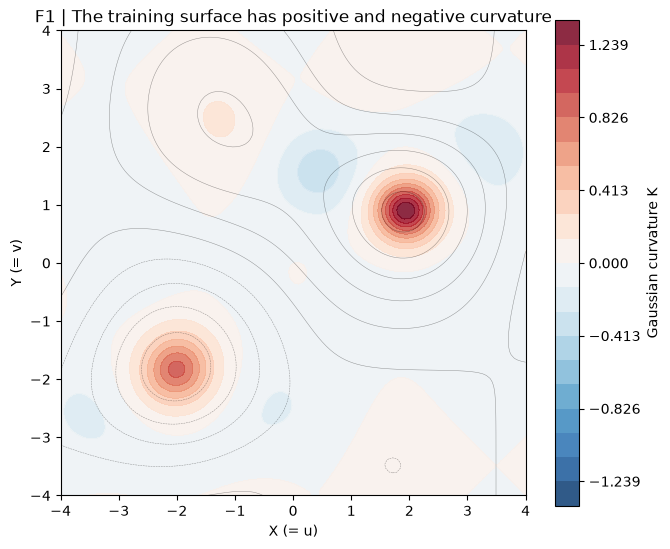

In [4]:
# ------------------------------------------------------------------ F1: Gaussian curvature of the training surface
K = K_func(X, Y)
K_limit = np.max(np.abs(K))

fig, ax = plt.subplots(figsize=(7.5, 6.3), dpi=100)
contour = ax.contourf(X, Y, K, levels=np.linspace(-K_limit, K_limit, 21), cmap="RdBu_r", alpha=0.85)
ax.contour(X, Y, Z, levels=9, colors="black", linewidths=0.35, alpha=0.4)  # height contours
fig.colorbar(contour, ax=ax, label="Gaussian curvature K")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("X (= u)")
ax.set_ylabel("Y (= v)")
ax.set_title("F1 | The training surface has positive and negative curvature")
show_figure(fig, "F1")


### 2.6 Numerical free-motion check
Eight starts are sampled in the chart window with modest random coordinate velocities.
Each free trajectory is integrated for 1,000 RK4 steps at dt=0.01. The left panel reports
absolute relative drift of squared physical speed on a log scale; values below 1e-16 are
displayed at that floor. The right panel shows the same paths over height contours.


8 free geodesics; dt=0.01; 1000 steps each; maximum drift=2.295e-11.


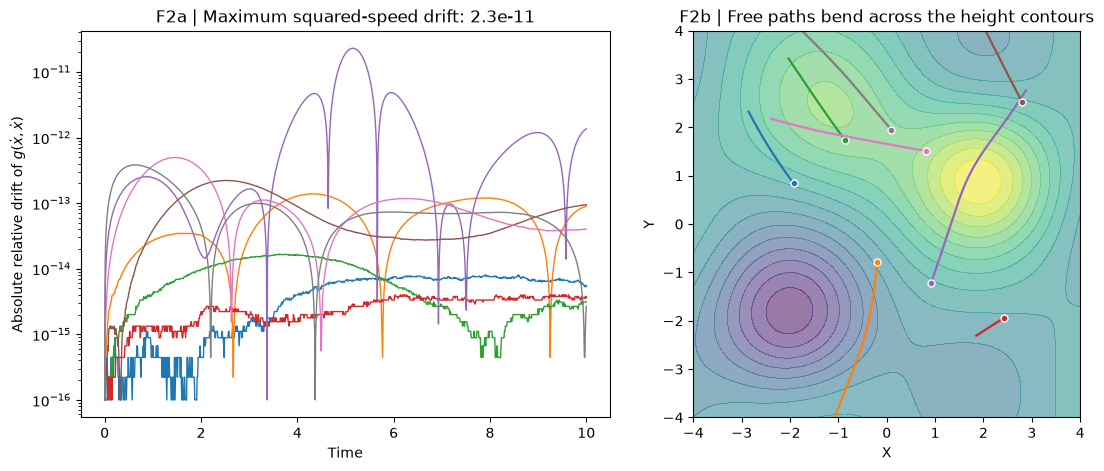

In [5]:
# ------------------------------------------------------------------ F2: conserved speed along free geodesics
rng_geometry = np.random.default_rng(2026)  # repeatable illustrations only; training was unseeded
initial_states = np.column_stack([
    rng_geometry.uniform(-3, 3, (8, 2)),      # chart positions (u, v)
    rng_geometry.normal(0, 0.25, (8, 2)),     # coordinate velocities (du/dt, dv/dt)
])


def squared_speed(state):
    """Physical squared speed g_ij dx^i/dt dx^j/dt of a chart state [u, v, du/dt, dv/dt]."""
    metric = env.g(state[0], state[1])
    dudt, dvdt = state[2], state[3]
    return metric[0, 0] * dudt * dudt + 2 * metric[0, 1] * dudt * dvdt + metric[1, 1] * dvdt * dvdt


geodesics = [integrate_free_motion(state, steps=1000) for state in initial_states]
drifts = []

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=100, layout="constrained")
axs[1].contourf(X, Y, Z, levels=20, cmap="viridis", alpha=0.55)  # height, as in visualize2d
for i, states in enumerate(geodesics):
    speed2 = np.array([squared_speed(state) for state in states])
    drift = np.abs(speed2 / speed2[0] - 1)
    drifts.append(drift)
    color = plt.cm.tab10(i)
    axs[0].semilogy(np.arange(len(states)) * 0.01, np.maximum(drift, 1e-16), color=color, linewidth=1)
    axs[1].plot(states[:, 0], states[:, 1], color=color, linewidth=1.6)
    axs[1].plot(states[0, 0], states[0, 1], "o", color=color, markersize=5, markeredgecolor="white")

max_drift = float(np.max(drifts))
axs[0].set_xlabel("Time")
axs[0].set_ylabel(r"Absolute relative drift of $g(\dot{x}, \dot{x})$")
axs[0].set_title(f"F2a | Maximum squared-speed drift: {max_drift:.1e}")
axs[1].set_xlim(-lim, lim)
axs[1].set_ylim(-lim, lim)
axs[1].set_aspect("equal", adjustable="box")
axs[1].set_xlabel("X")
axs[1].set_ylabel("Y")
axs[1].set_title("F2b | Free paths bend across the height contours")
print(f"8 free geodesics; dt=0.01; 1000 steps each; maximum drift={max_drift:.3e}.")
show_figure(fig, "F2")


Across the eight trajectories above, the maximum relative drift in squared speed is $2.3\times10^{-11}$ over 1,000 RK4 steps. The conserved quantity is the **metric speed** $g_{ij}\dot q^i\dot q^j$. Coordinate speed can change considerably as a trajectory crosses a slope. The environment test suite also checks fourth-order convergence under step refinement, conservation of angular momentum on surfaces of revolution and the tangent-frame transformations. [Environment tests](../env/test_environment.py)


## 3. From a physical thrust command to a learning signal

The simulator advances both bodies with RK4 at $\Delta t=0.01$. It maps the two policy outputs into an orthonormal tangent frame, enforces a unit-disk bound, and scales the result by 30. The resulting **coordinate** acceleration is held constant during the four RK4 stages of the pursuer's update. The target always has zero applied thrust. This convention makes the acceleration budget independent of the slope where a command is issued. [Environment](../env/environment.py)


### Observation dictionary

| Part | Size | Contents |
|---|---:|---|
| local_state | 8 | [u, v, velocity·e1, velocity·e2] for glider, then target |
| global_state | 12 | Embedded position (3) and velocity (3) for glider, then target |
| ego_features | 6 | [d·e1, d·e2, Euclidean norm of d, Δvelocity·e1, Δvelocity·e2, time_left] |

Here d is target minus glider position, and ego projections use the glider's tangent frame.
Each body's local velocity uses its own frame. The actor receives all 26 numbers; the critic
receives local and ego components, totaling 14.


In [6]:
# ------------------------------------------------------------------ orthonormal frame: round trip and thrust magnitude
rng_frames = np.random.default_rng(19)
points = rng_frames.uniform(-3, 3, (100, 2))
physical = rng_frames.normal(size=(100, 2))  # thrust in the orthonormal frame (e1, e2)

frame_error = 0.0
norm_error = 0.0
for point, vector in zip(points, physical):
    state = np.array([point[0], point[1], 0.0, 0.0])
    coordinate = env._change_basis_in_tangent_space(state, vector)                    # (e1, e2) -> (r_u, r_v)
    recovered = env._change_basis_in_tangent_space(state, coordinate, reverse=True)   # (r_u, r_v) -> (e1, e2)
    metric = env.g(point[0], point[1])
    # |x r_u + y r_v|^2 = g_ij x^i x^j must equal |a e1 + b e2|^2 = a^2 + b^2.
    squared_norm = (
        metric[0, 0] * coordinate[0]**2
        + 2 * metric[0, 1] * coordinate[0] * coordinate[1]
        + metric[1, 1] * coordinate[1]**2
    )
    frame_error = max(frame_error, np.max(np.abs(recovered - vector)))
    norm_error = max(norm_error, abs(squared_norm - vector @ vector))

assert frame_error < 1e-12 and norm_error < 1e-12
print(f"100 frames: round-trip error {frame_error:.2e}; physical squared-norm error {norm_error:.2e}.")


100 frames: round-trip error 2.22e-16; physical squared-norm error 2.66e-15.


### Swept success test
Let $p_0,p_1$ be glider-minus-target embedded positions at the beginning and end of a step.
Minimising $\|p_0+s(p_1-p_0)\|^2$ on $[0,1]$ gives
$$s^*=\operatorname{clip}\left(-\frac{p_0\cdot(p_1-p_0)}{\|p_1-p_0\|^2},0,1\right).$$
This segment check prevents tunnelling through the target between samples. The denominator is floored at $10^{-12}$, so the zero-motion case uses the starting separation. The check in `_get_termination` is:

```python
p0, p1 = prev_g - prev_t, g - t
seg = p1 - p0
s = np.clip(-(p0 @ seg) / max(seg @ seg, 1e-12), 0.0, 1.0)
if np.linalg.norm(p0 + s * seg) < self.complete_region:
    self.is_terminated, self.reason = True, "completed"
```
The "too far" and "timeout" checks follow only if this one fails, in that order.


### Distance used for shaping
For chart endpoints $q_0,q_1$, set $q_i=q_0+\frac{i}{N-1}(q_1-q_0)$ and lift each sample to
$r(q_i)$. The estimator is
$$\hat d_N=\sum_{i=0}^{N-2}\|r(q_{i+1})-r(q_i)\|_2,\qquad N=10.$$
It is a polyline estimate with vertices on the surface; individual chord segments need not lie
on the surface. N=2 is the ambient chord. As N grows, it approaches the length of the lifted
chart-straight path, which need not be a geodesic. It is computed by `env._calculate_distance(N)`. A geodesic boundary-value solve each step
would be substantially more involved.


For a section with $f(u,0)=u^2$ on $0\le u\le1$, the reference arc length is $\int_0^1\sqrt{1+4u^2}\,du=\sqrt{5}/2+\operatorname{asinh}(2)/4$. This isolates the error from replacing the selected curve by chords. It leaves out the separate geometric question of whether the selected path is shortest.


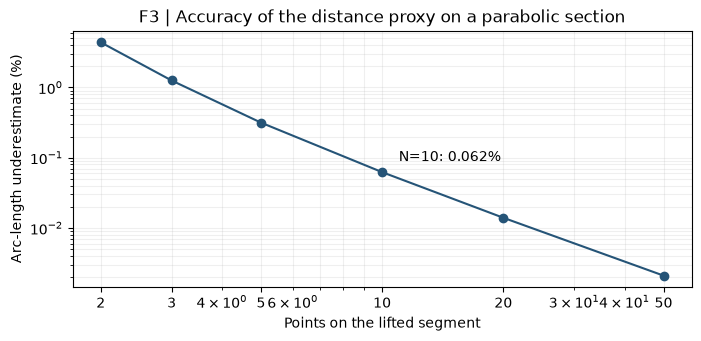

In [7]:
exact_length = np.sqrt(5) / 2 + np.arcsinh(2) / 4
point_counts = np.array([2, 3, 5, 10, 20, 50])
errors = []
for count in point_counts:
    chart = np.linspace(0, 1, count)
    length = np.hypot(np.diff(chart), np.diff(chart**2)).sum()
    errors.append(100 * (exact_length - length) / exact_length)

fig, ax = plt.subplots(figsize=(6.9, 3.3), layout="constrained")
ax.loglog(point_counts, errors, "o-", color="#255477")
ax.set(xlabel="Points on the lifted segment", ylabel="Arc-length underestimate (%)",
       title="F3 | Accuracy of the distance proxy on a parabolic section")
ax.set_xticks(point_counts, point_counts)
ax.grid(alpha=0.2, which="both")
ax.annotate(f"N=10: {errors[3]:.3f}%", (10, errors[3]), xytext=(12, 8), textcoords="offset points")
show_figure(fig)


### Reward
With $\hat d_t$ the lifted-polyline estimate (`previous_distance`, `distance`) and step penalty $c_t$ (`time_penalty`),
$$r_t=\beta(\hat d_{t-1}-\hat d_t)-c_t+5\,\mathbf 1_{\mathrm{success}},\qquad \beta=10\ (\texttt{distance\_reward\_scale}).$$
The penalty starts at 0.01 and is increased by 1e-4 *before* it is subtracted, so $c_t=0.01+10^{-4}t$ for step $t=1,2,\dots$. Waiting becomes progressively more costly; too-far and time-out add no terminal penalty. `_get_reward` in the environment is:

```python
distance = self._calculate_distance(self.N)
delta = self.distance_reward_scale * (self.previous_distance - distance)
self.time_penalty += 0.0001
self.previous_distance = distance
if self.reason == "completed":
    delta += 5
return delta - self.time_penalty
```


## 4. Stochastic actor, value function and PPO updates

The actor and critic are separate LeakyReLU MLPs. The actor uses $26\to64\to64\to2$ with two additional trainable log standard deviations (6,020 parameters). The critic uses $14\to64\to64\to1$ (5,185). Both see chart kinematics and relative motion. The actor also receives the ambient coordinates and velocities. This split lets the experiment vary critic inputs without changing the policy representation. [Networks](../agent/network.py) · [Rollout buffer and optimizer](../agent/ppo.py)

At each step the actor defines a diagonal Gaussian, with mean $4\tanh(h/4)$ and state-independent log standard deviations clamped to $[-3,0.5]$. A fresh draw $z_t$ supplies the command $\tanh z_t$ to the environment. Orthogonal initialization with gain $\sqrt 2$ in the hidden layers, 0.01 at the actor head and 1 at the critic head keeps initial policy means close to zero.


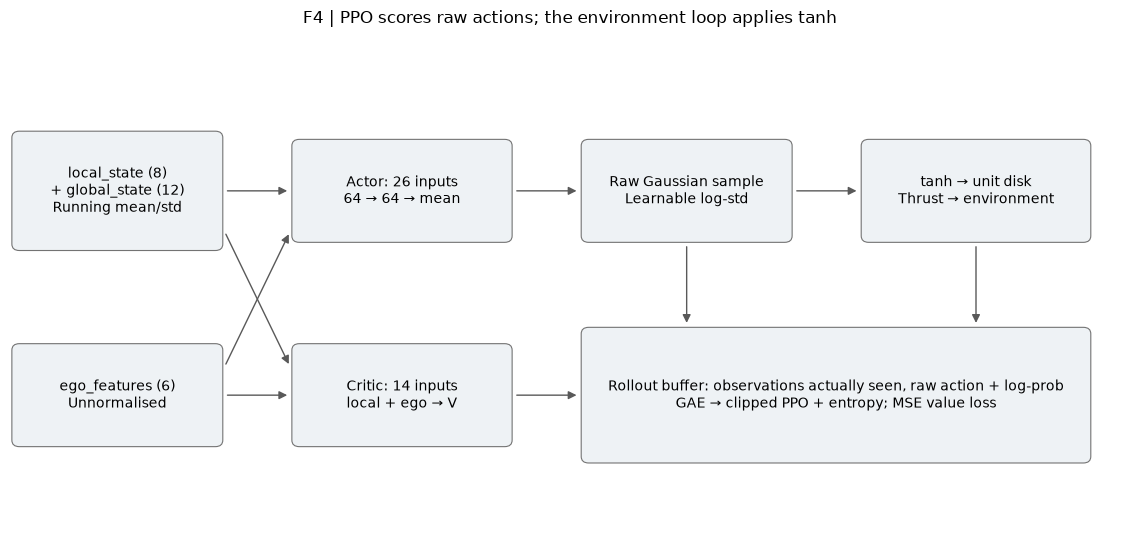

In [8]:
# ------------------------------------------------------------------ F4: data flow of the PPO implementation
fig, ax = plt.subplots(figsize=(11.5, 5.5), dpi=100)
ax.set_xlim(0, 12)
ax.set_ylim(0, 6)
ax.axis("off")


def draw_box(x, y, width, height, text, color="#EEF2F5"):
    """Rounded box with centred text."""
    ax.add_patch(FancyBboxPatch((x, y), width, height, boxstyle="round,pad=0.08", fc=color, ec="0.45", lw=0.8))
    ax.text(x + width / 2, y + height / 2, text, ha="center", va="center", fontsize=10)


def draw_arrow(start, end):
    """Arrow between two points of the diagram."""
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=12, color="0.35", lw=1))


draw_box(0.1, 3.5, 2.1, 1.3, "local_state (8)\n+ global_state (12)\nRunning mean/std")
draw_box(0.1, 1.1, 2.1, 1.1, "ego_features (6)\nUnnormalised")
draw_box(3.1, 3.6, 2.2, 1.1, "Actor: 26 inputs\n64 → 64 → mean")
draw_box(3.1, 1.1, 2.2, 1.1, "Critic: 14 inputs\nlocal + ego → V")
draw_box(6.2, 3.6, 2.1, 1.1, "Raw Gaussian sample\nLearnable log-std")
draw_box(9.2, 3.6, 2.3, 1.1, "tanh → unit disk\nThrust → environment")
draw_box(6.2, 0.9, 5.3, 1.5, "Rollout buffer: observations actually seen, raw action + log-prob\nGAE → clipped PPO + entropy; MSE value loss")

draw_arrow((2.3, 4.15), (3.0, 4.15))
draw_arrow((2.3, 1.65), (3.0, 1.65))
draw_arrow((2.3, 3.65), (3.0, 2.0))
draw_arrow((2.3, 2.0), (3.0, 3.65))
draw_arrow((5.4, 4.15), (6.1, 4.15))
draw_arrow((8.4, 4.15), (9.1, 4.15))
draw_arrow((7.25, 3.5), (7.25, 2.5))
draw_arrow((10.35, 3.5), (10.35, 2.5))
draw_arrow((5.4, 1.65), (6.1, 1.65))

ax.set_title("F4 | PPO scores raw actions; the environment loop applies tanh", pad=12)
fig.tight_layout()
show_figure(fig, "F4")


### The likelihood ratio belongs to the sampled variable

PPO stores the **raw Gaussian draw** $z_t$, its joint log probability and the normalized observations used for that action. This gives $\rho_t=\exp[\log\pi_\theta(z_t\mid x_t)-\log\pi_{\rm old}(z_t\mid x_t)]$ when the rollout is reused. Tanh and the radial thrust bound belong to the environment-facing map. Outside the disk, radial rescaling is many-to-one. Computing a Gaussian log probability at that rescaled thrust would assign the probability of a different action.

The following numerical check holds the likelihood parameters fixed. A stored raw draw gives ratio one, including when its physical command has reached the thrust limit. Substituting its bounded command into the numerator breaks the identity.


In [9]:
draw = np.array([1.5, -2.0])
mu = np.array([0.2, -0.1])
sigma = np.array([0.8, 1.1])

def log_density(value):
    return -0.5 * np.sum(((value - mu) / sigma)**2 + np.log(2 * np.pi * sigma**2))

command = np.tanh(draw)
physical_direction = command / max(1.0, np.linalg.norm(command))
old_logp = log_density(draw)
raw_ratio = np.exp(log_density(draw) - old_logp)
wrong_ratio = np.exp(log_density(physical_direction) - old_logp)
assert np.isclose(raw_ratio, 1.0) and not np.isclose(wrong_ratio, 1.0)
print(f"Unchanged policy, stored draw: {raw_ratio:.3f}. Substituting bounded thrust: {wrong_ratio:.3f}.")


Unchanged policy, stored draw: 1.000. Substituting bounded thrust: 11.765.


### PPO-Clip and generalized advantage estimation
For the stored raw action $a_t=z_t$, $r_t(\theta)=\exp(\log\pi_\theta(a_t|s_t)-\log\pi_{\rm old}(a_t|s_t))$.
The clipped actor objective is
$$L^{\rm clip}=\mathbb E\left[\min\{r_t\hat A_t,
\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)\hat A_t\}\right],\qquad\epsilon=0.2.$$
An entropy bonus of 0.005 encourages exploration; the critic uses mean squared error on returns.
GAE is computed backwards:
$$\delta_t=r_t^{\rm reward}+\gamma(1-d_t)V(s_{t+1})-V(s_t),\qquad
A_t=\delta_t+\gamma\lambda(1-d_t)A_{t+1}.$$
Here $\gamma=0.99$, $\lambda=0.95$, and $d_t$ is the stored episode-end flag.
Returns are formed before advantages are normalised across the complete rollout.


### Engineering details that affect the update

| Decision | Implementation | Why it matters |
|---|---|---|
| Observation scaling | Merge running means and second moments in float64 for the 8 local and 12 global features. Pass the 6 ego features in physical units. Store the post-normalization observation in the rollout. | Replaying a transition uses the exact inputs on which its action probability was computed. The distance and time features retain their physical scales. |
| Episode boundaries | Stop the GAE trace at a capture, boundary exit or time limit. Bootstrap from the critic when a rollout ends mid-episode. | A reset state belongs to a new pursuit. The time remaining is observable, so the finite-horizon boundary is part of the task. |
| Advantage normalization | Compute returns as $A_t+V_t$ before standardizing advantages over the rollout. | Critic targets preserve the reward scale and the actor sees a consistent scale across minibatches. |
| Update budget | Collect 2,048 transitions, shuffle minibatches of 64, use at most 10 epochs and clip the policy ratio at 0.2. | Reuse the expensive physics transitions while constraining the size of the policy update. |
| Optimization | Separate Adam optimizers, initial learning rate $3\times10^{-4}$ with linear decay, $\epsilon=10^{-5}$, gradient norms capped at 0.5, entropy coefficient 0.005. Stop after an epoch whose mean approximate KL exceeds 0.015. | Gradient clipping, the policy ratio and the epoch KL each monitor a different aspect of update size. |

For each update, the trainer records approximate KL, clip fraction, explained variance, entropy and the per-component log standard deviations. These measurements let us examine how a design change affected optimization even when final capture rates overlap. [Training loop](../agent/train.py) · [Configuration](../configs/ppo_config.yaml)


## 5. Checkpoint evaluation on different landscapes 

Each surface was evaluated for 200 episodes using the released checkpoint and the stochastic action-selection method from `scripts/demo.py` (`Sandbox.pick_action`). Reset seeds 0–199 were reused on every surface. The CPU action sampler was seeded once per surface with `20261121`. The weights, local and global observation statistics, and reset options were loaded from `baseline.pt`. Only the height function changed. A capture is an episode ending with `info["reason"] == "completed"`.

| Surface | Captures / episodes | Capture rate | Timeouts | Boundary exits |
|---|---:|---:|---:|---:|
| Training terrain (three Gaussian components and a ripple) | 196/200 | 98.0% | 0 | 4 |
| Horizontal plane, $f=0$ | 196/200 | 98.0% | 1 | 3 |
| Inclined plane, $f=u+v$ | 100/200 | 50.0% | 40 | 60 |
| Single Gaussian hill, $f=\exp(-u^2-v^2)$ | 192/200 | 96.0% | 1 | 7 |

The horizontal plane matched the training-terrain capture rate (98%). The single hill reached 96%. The largest change occurred on the inclined plane, where 100 of 200 pursuits succeeded. The other 100 episodes ended in 60 boundary exits and 40 timeouts. Both planes have zero Gaussian curvature. Tilting the plane changes the chart metric, the embedded velocities and the region satisfying the spatial bound $\max(|u|,|v|,|f(u,v)|)\leq 15$. The experiment measures their combined effect.

The author’s independent interactive session recorded **98/100** on the training terrain with the HUD showing `stochastic`. It used its own random start and action sequences. [Demo entry point](../scripts/demo.py)


### Replay on the four surfaces

The cells below restore `models/baseline.pt` (SHA-256 `4d1dbb0e1c6b218c076dbd21c80513a4df58b01450d34a72cc51e89edd6b4f9f`). The headless evaluation calls the demo’s policy method and the simulator’s ordinary reset and step methods. The per-episode table `episode_results` retains the surface, reset seed, terminal reason and number of steps for all 800 trials.


In [10]:
import hashlib
from types import SimpleNamespace
import torch
from agent.network import Actor
from agent.ppo import RunningMeanStd
from scripts.demo import Sandbox

checkpoint_path = PROJECT_DIR / "models" / "baseline.pt"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
print("Checkpoint SHA-256:", hashlib.sha256(checkpoint_path.read_bytes()).hexdigest())
print("PyTorch", torch.__version__, "· CPU inference")
actor = Actor(checkpoint["actor_obs_dim"], checkpoint["act_dim"],
              hidden=checkpoint["config"]["model"]["hidden_size"])
actor.load_state_dict(checkpoint["actor_state_dict"])
controller = SimpleNamespace(
    actor=actor.eval(), actor_obs_dim=checkpoint["actor_obs_dim"],
    critic_obs_dim=checkpoint["critic_obs_dim"], deterministic=False,
    local_rms=RunningMeanStd(), global_rms=RunningMeanStd(),
)
controller.local_rms.load_state_dict(checkpoint["local_rms"])
controller.global_rms.load_state_dict(checkpoint["global_rms"])


Checkpoint SHA-256: 4d1dbb0e1c6b218c076dbd21c80513a4df58b01450d34a72cc51e89edd6b4f9f
PyTorch 2.5.1+cu121 · CPU inference


In [11]:
def evaluate_surface(height, reset_seeds=range(200), action_seed=20261121):
    simulation = GeodesicGliderEnv(sp.Matrix([u, v, height]), cords=[u, v])
    episodes = []
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(action_seed)
            for seed in reset_seeds:
                controller.obs, _ = simulation.reset(seed=seed, options=checkpoint["options"])
                steps = 0
                while True:
                    action = Sandbox.pick_action(controller)
                    controller.obs, _, terminated, truncated, info = simulation.step(action)
                    steps += 1
                    if terminated or truncated:
                        episodes.append({"seed": seed, "outcome": info["reason"], "steps": steps})
                        break
    finally:
        simulation.close()
    return pd.DataFrame(episodes)

surfaces = {
    "Training terrain": sp.sympify(checkpoint["manifold_expr"]),
    "Horizontal plane": sp.Integer(0),
    "Inclined plane": u + v,
    "Single hill": sp.exp(-u**2 - v**2),
}
episode_results = pd.concat(
    {name: evaluate_surface(height) for name, height in surfaces.items()},
    names=["surface", "episode"],
).reset_index(level="episode", drop=True)
counts = pd.crosstab(episode_results.index, episode_results["outcome"]).reindex(
    index=list(surfaces), columns=["completed", "timeout", "too far"], fill_value=0,
)
counts.columns = ["captures", "timeouts", "boundary exits"]
counts["episodes"] = counts.sum(axis=1)
counts["capture rate (%)"] = 100 * counts["captures"] / counts["episodes"]
display(counts)


,captures,timeouts,boundary exits,episodes,capture rate (%)
row_0,,,,,
Training terrain,196,0,4,200,98.0
Horizontal plane,196,1,3,200,98.0
Inclined plane,100,40,60,200,50.0
Single hill,192,1,7,200,96.0


## 6. Which engineering choices affected learning?

The controlled campaign compares 18 single-factor changes with the baseline under a 60,000-step training budget. It contains 46 completed runs across 19 configurations, including five baseline runs. The score for one run is the capture fraction in its **last complete, non-overlapping block of 30 training episodes**. Each replicate contributes one score. The checkpoint figures above instead measure a fixed policy after training.

The code selects the latest finished run for each run name in the campaign, reads raw block and optimizer histories from the local W&B export and shows individual replicates. With two to five runs per configuration, the spread of the points matters as much as the mean. [Experiment archive](wandb_export.zip)


In [12]:
archive_path = PROJECT_DIR / "notebooks" / "wandb_export.zip"
with zipfile.ZipFile(archive_path) as zf:
    members = {Path(name).name: name for name in zf.namelist() if not name.endswith("/")}
    def read_history(name):
        with zf.open(members[name]) as fh:
            return pd.read_csv(fh)
    runs = read_history("runs_overview.csv")
    candidates = runs[runs["state"].eq("finished") & runs["group"].notna()].copy()
    configs = {rid: json.loads(zf.read(members[f"{rid}_config.json"])) for rid in candidates["id"]}
    candidates = candidates[candidates["id"].map(lambda rid: configs[rid]["training"]["total_timesteps"] == 60000)]
    candidates["created_at"] = pd.to_datetime(candidates["created_at"], utc=True)
    campaign = candidates.sort_values("created_at").drop_duplicates("name", keep="last")
    histories = {rid: read_history(f"{rid}.csv").sort_values("_step") for rid in campaign["id"]}

records = []
for row in campaign.to_dict("records"):
    history = histories[row["id"]]
    final_block = history.dropna(subset=["episode/success_rate"]).iloc[-1]
    late_updates = history.dropna(subset=["train/approx_kl"]).tail(5)
    records.append({
        "group": row["group"], "run": row["id"],
        "capture": final_block["episode/success_rate"],
        "timeout": final_block["episode/timeout_rate"], "exit": final_block["episode/too_far_rate"],
        "runtime": row["summary._runtime"], "KL": late_updates["train/approx_kl"].mean(),
        "clip fraction": late_updates["train/clip_fraction"].mean(),
    })
scores = pd.DataFrame(records)
assert len(scores) == 46 and scores["group"].nunique() == 19
assert np.allclose(scores[["capture", "timeout", "exit"]].sum(axis=1), 1)
summary = scores.groupby("group").agg(
    runs=("run", "count"), mean=("capture", "mean"), low=("capture", "min"),
    high=("capture", "max"), runtime=("runtime", "mean"), KL=("KL", "mean"),
    clip_fraction=("clip fraction", "mean"),
)


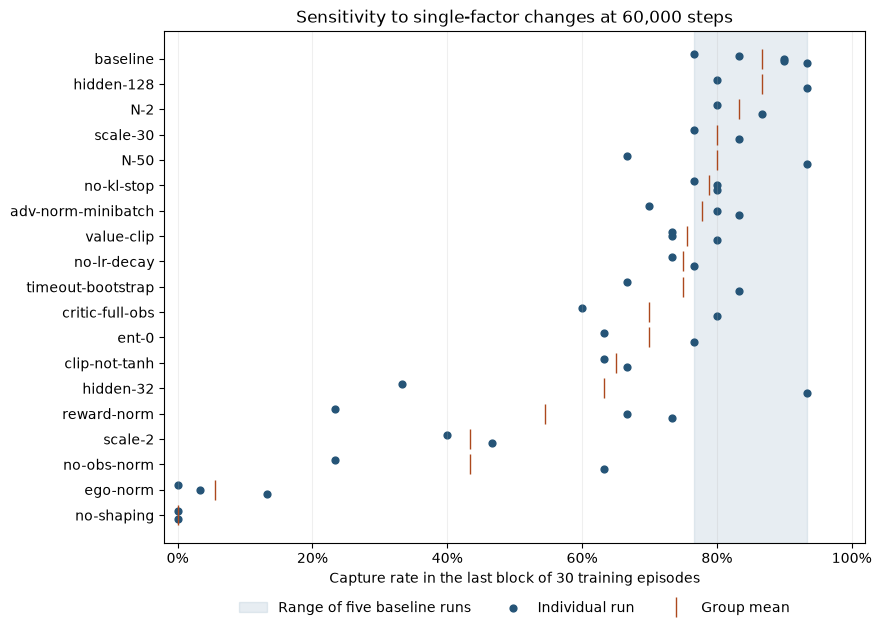

In [13]:
order = ["baseline", *summary.drop(index="baseline").sort_values("mean", ascending=False).index]
fig, ax = plt.subplots(figsize=(8.7, 6.2), layout="constrained")
base = summary.loc["baseline"]
ax.axvspan(base.low, base.high, color="#608bac", alpha=0.15, label="Range of five baseline runs")
for i, group in enumerate(order):
    values = scores.loc[scores.group.eq(group), "capture"].sort_values()
    ax.scatter(values, i + np.linspace(-0.17, 0.17, len(values)), s=24, color="#255477",
               label="Individual run" if i == 0 else None)
    ax.plot(summary.at[group, "mean"], i, marker="|", markersize=15, color="#ac481d", lw=0,
            label="Group mean" if i == 0 else None)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(-0.02, 1.02)
ax.set_xlabel("Capture rate in the last block of 30 training episodes")
ax.set_title("Sensitivity to single-factor changes at 60,000 steps")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False)
ax.grid(axis="x", alpha=0.2)
show_figure(fig)


**Reward shaping and representation.** The five baseline runs averaged 86.7% (range 76.7–93.3%). Removing the progress reward left both runs at 0/30 captures in the last block, with 96.7% of episodes ending in boundary exits on average. Reducing its coefficient from 10 to 2 yielded 43.3%. Standardizing the six ego features reduced mean success to 5.6%, while removing normalization from the local and global features yielded 43.3%. Doubling hidden width to 128 gave the same mean as the baseline, 86.7%. Under this budget, changing the learning signal or the scale of the inputs had the larger observed effect.


In [14]:
focus = ["baseline", "no-shaping", "scale-2", "ego-norm", "no-obs-norm",
         "hidden-128", "N-2", "N-50", "no-lr-decay", "no-kl-stop"]
comparison = summary.loc[focus].copy()
comparison[["mean", "low", "high", "clip_fraction"]] *= 100
comparison = comparison.rename(columns={
    "mean": "capture %", "low": "min %", "high": "max %",
    "runtime": "runtime (s)", "clip_fraction": "late clip %",
})
display(comparison.round({"capture %": 1, "min %": 1, "max %": 1,
                          "runtime (s)": 1, "KL": 5, "late clip %": 2}))


,runs,capture %,min %,max %,runtime (s),KL,late clip %
group,,,,,,,
baseline,5,86.7,76.7,93.3,156.5,0.00449,5.15
no-shaping,2,0.0,0.0,0.0,156.8,0.00199,1.46
scale-2,2,43.3,40.0,46.7,157.1,0.00272,2.53
ego-norm,3,5.6,0.0,13.3,158.7,0.00427,5.17
no-obs-norm,2,43.3,23.3,63.3,149.5,0.00387,4.39
hidden-128,2,86.7,80.0,93.3,158.2,0.00450,5.19
N-2,2,83.3,80.0,86.7,150.3,0.00337,3.44
N-50,2,80.0,66.7,93.3,186.4,0.00397,4.21
no-lr-decay,2,75.0,73.3,76.7,158.4,0.00840,11.27


**Computation and update size.** Increasing the lifted path resolution from 10 to 50 points raised mean run time from 156.5 to 186.4 seconds (+19.1%) on the logged machine. Final capture-rate ranges overlapped. This comparison motivated the ten-point estimator in the environment loop. Keeping the learning rate constant changed late clip fraction from 5.1% to 11.3% and approximate KL from 0.0045 to 0.0084. These measurements support decay as a way to keep late policy updates small. The small number of replicates leaves its effect on final capture rate uncertain.

**Conclusion.** The controller combines metric-consistent physics, a bounded physical action and relative kinematics with a compact stochastic policy. The frozen checkpoint captured 98% of targets on the training terrain, 98% on the horizontal plane, 96% on the Gaussian hill and 50% on the inclined plane. The inclined-plane result limits the claim of transfer even within this family of graph surfaces. The ablations help explain which implementation details earned their place in that design, especially the dense progress reward and the selective scaling of observations. The transfer measurements cover the four stated surfaces and initial-state distribution. Arbitrary graph geometries and extrapolation to other launch distributions remain outside the evaluation.


## Reproduction

From the project root, install the project and notebook dependencies using the commands in the [README](../README.md#reproduction). Place the released checkpoint at `models/baseline.pt` and the exported histories at `notebooks/wandb_export.zip`. Select **Run All** using the project environment. The evaluation runs 800 episodes on CPU. The ablation analysis reads the archive locally. The simulator checks can be run separately with `python -m pytest -q env/test_environment.py`.


## References
- Schulman et al., "Proximal Policy Optimization Algorithms" (2017).
- Schulman et al., "High-Dimensional Continuous Control Using Generalized Advantage Estimation" (2016).
- Pardo et al., "Time Limits in Reinforcement Learning" (ICML 2018).
- Andrychowicz et al., "What Matters in On-Policy Reinforcement Learning? A Large-Scale Empirical Study" (2021).
- Huang et al., "The 37 Implementation Details of Proximal Policy Optimization" (ICLR Blog Track 2022).
- do Carmo, "Differential Geometry of Curves and Surfaces".
